# 04 · Boiling point: worked one-shot prediction workflow

<h1 style="color:#1D4E89;">Step 0: Conditioning the Coding Assistant</h1>

        This completed notebook shows one transparent, CPU-friendly path from molecular SMILES to boiling-point predictions. It keeps the supplied data immutable, records every decision, and treats the final test set as a one-time estimate. The code is intentionally compact enough to read during a workshop.

        <h3 style="color:#B05E27;">One-shot implementation plan</h3>

        1. Load the local NIST-derived table and audit chemical identities and labels.
        2. Canonicalize eligible single-component molecules, freeze reproducible splits, and derive all features from SMILES.
        3. Compare two fast tree-based regressors and a descriptor/fingerprint ablation on validation data.
        4. Make one validation-motivated representation improvement, then evaluate the frozen choice once on test data and package inference.


### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


### Locate the dataset and organize the experiment

Code Summary: Locates the boiling-point dataset, sets a reproducible seed, and creates experiment folders. Acquired NIST data is preferred over the packaged fallback, and inputs will be derived only from SMILES.


In [1]:
from __future__ import annotations

import hashlib
import json
import platform
import subprocess
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdkit
import sklearn
from IPython.display import display
from rdkit import Chem, DataStructs
from rdkit.Chem import DataStructs, Descriptors, Lipinski, rdFingerprintGenerator, rdMolDescriptors
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

WORKFLOW_STARTED = time.perf_counter()

def find_repository_root() -> Path:
    """Work from the repository root, module, or examples folder."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / '01_boiling_point').exists() and (candidate / 'pyproject.toml').exists():
            return candidate.resolve()
    raise FileNotFoundError('Start from the workshop repository root or 01_boiling_point.')

REPO = find_repository_root()
MODULE = REPO / '01_boiling_point'
ACQUIRED_DATA = MODULE / 'outputs/nist_acquisition/NIST_BP_SMILES.parquet'
FALLBACK_DATA = MODULE / 'data/CompoundData.parquet'
DATA_FILE = ACQUIRED_DATA if ACQUIRED_DATA.exists() else FALLBACK_DATA
DATA_KIND = 'NIST acquisition output' if DATA_FILE == ACQUIRED_DATA else 'prepared fallback'
OUTPUT = MODULE / 'outputs/bp_one_shot_2'
FIGURES = OUTPUT / 'figures'
EXPERIMENTS = OUTPUT / 'experiments'
for folder in [OUTPUT, FIGURES, EXPERIMENTS]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = 'BP'
SMILES = 'SMILES'
FP_RADIUS = 2  # radius 2 corresponds to ECFP-style local neighborhoods of diameter 4
DESCRIPTOR_NAMES = [
    'MolWt', 'MolLogP', 'TPSA', 'HBD', 'HBA', 'RotatableBonds', 'RingCount',
    'AromaticRings', 'FractionCSP3', 'HeavyAtoms', 'FormalCharge',
]

plt.style.use('seaborn-v0_8-whitegrid')
print(f'Repository: {REPO}')
print(f'Data source: {DATA_FILE.relative_to(REPO)} ({DATA_KIND})')
print(f'Artifacts: {OUTPUT.relative_to(REPO)}')
print('Policy: use only SMILES-derived features; BP is never a feature.')


Repository: C:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code
Data source: 01_boiling_point\outputs\nist_acquisition\NIST_BP_SMILES.parquet (NIST acquisition output)
Artifacts: 01_boiling_point\outputs\bp_one_shot_2
Policy: use only SMILES-derived features; BP is never a feature.


<h1 style="color:#1D4E89;">Step 1: Set Goal</h1>

        **Goal.** Predict the dataset's reported boiling point from a molecular SMILES string. The primary model-selection measure is validation mean absolute error (MAE) in kelvin; RMSE and R² add complementary information about large errors and explained variation.

        **Workshop success criterion.** Before fitting, we will consider the workflow successful if the frozen model beats a training-median baseline on held-out MAE. This is a useful learning and screening demonstration, not an industrial accuracy guarantee. The retained provenance confirms kelvin values but does not establish a common measurement pressure for every record, so predictions should be described as predictions of this dataset's reported labels.


<h1 style="color:#1D4E89;">Step 2: Define Inputs and Outputs</h1>

        **Input:** one valid, single-component SMILES string, or a list of them.

        **Output:** predicted boiling point in K (and a displayed Celsius conversion), plus an input-status and a similarity-based applicability indicator. Invalid SMILES and multi-component entries are rejected explicitly. A valid but chemically unfamiliar molecule can receive a prediction, but low similarity to the training structures warns that it lies outside the local training support. Similarity is a diagnostic, not a calibrated uncertainty interval.


<h1 style="color:#1D4E89;">Step 3: Collect Data</h1>

        Collection is already complete. This notebook selects one local table, never combines sources, and does not rerun NIST acquisition. The preferred table is the cleaned `NIST_BP_SMILES.parquet` written by the preceding acquisition notebook; its neighboring cleaning audit records that `BP` is in K. If that file is unavailable, the configuration selects the prepared fallback and prints that choice.


<h2 style="color:#1D4E89;">Step 4: Examine Data</h2>

        First inspect the supplied table and perform deterministic checks needed to define usable chemical identities. These checks are not a search for favorable labels: they identify absent values, invalid structures, multiple components, and equivalent structures. Temperatures are only checked for finite, physically implausible values; an unusual value is flagged for review rather than automatically discarded.


### Audit molecular identities and boiling-point values

Code Summary: Audits molecular identities, missing targets, molecular components, charges, and temperature ranges before modeling. Temperature bounds flag suspicious records but cannot establish their source units.


In [2]:
raw = pd.read_parquet(DATA_FILE).copy()
if not {SMILES, TARGET}.issubset(raw.columns):
    raise ValueError(f'Expected {SMILES!r} and {TARGET!r}; found {raw.columns.tolist()}')
raw = raw.reset_index(names='source_row')
raw[TARGET] = pd.to_numeric(raw[TARGET], errors='coerce')

def canonicalize_smiles(value):
    if not isinstance(value, str) or not value.strip():
        return None
    molecule = Chem.MolFromSmiles(value)
    return Chem.MolToSmiles(molecule, canonical=True, isomericSmiles=True) if molecule else None

raw['canonical_SMILES'] = raw[SMILES].map(canonicalize_smiles)
raw['valid_smiles'] = raw['canonical_SMILES'].notna()
raw['single_component'] = raw['canonical_SMILES'].fillna('').str.count(r'\.') == 0
raw['finite_target'] = np.isfinite(raw[TARGET])
raw['plausible_temperature'] = raw[TARGET].between(1.0, 2000.0, inclusive='both')
raw['charged'] = raw['canonical_SMILES'].fillna('').str.contains(r'\[.*[+-].*\]', regex=True)
raw['has_stereochemistry'] = raw['canonical_SMILES'].fillna('').str.contains(r'[@/\\]', regex=True)

audit = pd.DataFrame([{
    'source_rows': len(raw),
    'missing_or_invalid_SMILES': int((~raw.valid_smiles).sum()),
    'multi_component_SMILES': int((raw.valid_smiles & ~raw.single_component).sum()),
    'missing_or_nonfinite_BP': int((~raw.finite_target).sum()),
    'outside_1_to_2000_K': int((raw.finite_target & ~raw.plausible_temperature).sum()),
    'charged_structures_flagged': int(raw.charged.sum()),
    'stereochemical_SMILES_flagged': int(raw.has_stereochemistry.sum()),
    'exact_duplicate_rows': int(raw.duplicated([SMILES, TARGET]).sum()),
    'source': DATA_KIND,
    'units': 'K, established by the preceding NIST acquisition notebook and cleaning audit' if DATA_FILE == ACQUIRED_DATA else 'check fallback provenance before scientific reuse',
}])
audit.to_csv(OUTPUT / 'cleaning_audit.csv', index=False)
display(raw[["source_row", SMILES, TARGET]].head())
display(audit.T.rename(columns={0: 'count_or_note'}))
print('Schema:')
print(raw[[SMILES, TARGET]].dtypes)


,source_row,SMILES,BP
0,0,C,111.00
1,1,C#C,189.00
2,2,C#C/C(C)=C/C,342.00
3,3,C#C/C(C)=C/CC,366.15
4,4,C#C/C=C/C,323.65


,count_or_note
source_rows,4659
missing_or_invalid_SMILES,0
multi_component_SMILES,1
missing_or_nonfinite_BP,0
outside_1_to_2000_K,0
charged_structures_flagged,88
stereochemical_SMILES_flagged,432
exact_duplicate_rows,0
source,NIST acquisition output
units,"K, established by the preceding NIST acquisiti..."


Schema:
SMILES     object
BP        float64
dtype: object


### Inspect flagged records and repeated measurements

Code Summary: Displays flagged records and boiling-point disagreements among repeated molecular structures so questionable measurements can be examined before cleaning.


In [3]:
# Show only a small review table: flags guide inspection but do not decide model quality.
review_columns = ['source_row', SMILES, TARGET, 'canonical_SMILES', 'valid_smiles',
                  'single_component', 'finite_target', 'plausible_temperature', 'charged']
flagged = raw.loc[
    (~raw.valid_smiles) | (~raw.single_component) | (~raw.finite_target) |
    (~raw.plausible_temperature) | raw.charged,
    review_columns,
]
print(f'Flagged rows for review: {len(flagged)}')
display(flagged.head(12))

# Equivalent canonical structures are audited separately; repeated measurements are not silently discarded.
identity_counts = raw.loc[raw.valid_smiles].groupby('canonical_SMILES').agg(
    records=(TARGET, 'size'), BP_min=(TARGET, 'min'), BP_max=(TARGET, 'max')
)
repeated_identities = identity_counts.query('records > 1').sort_values(['records', 'BP_max'], ascending=False)
print(f'Canonical identities with repeated records: {len(repeated_identities)}')
display(repeated_identities.head(10))


Flagged rows for review: 89


,source_row,SMILES,BP,canonical_SMILES,valid_smiles,single_component,finite_target,plausible_temperature,charged
662,662,C=CC[N+](=O)[O-],400.70,C=CC[N+](=O)[O-],True,True,True,True,True
700,700,C=C[N+](=O)[O-],371.70,C=C[N+](=O)[O-],True,True,True,True,True
858,858,CC(=O)c1ccc([N+](=O)[O-])cc1,475.20,CC(=O)c1ccc([N+](=O)[O-])cc1,True,True,True,True,True
865,865,CC(=O)c1cccc([N+](=O)[O-])c1,475.20,CC(=O)c1cccc([N+](=O)[O-])c1,True,True,True,True,True
952,952,CC(C)(C)[N+](=O)[O-],400.40,CC(C)(C)[N+](=O)[O-],True,True,True,True,True
991,991,CC(C)([N+](=O)[O-])[N+](=O)[O-],458.70,CC(C)([N+](=O)[O-])[N+](=O)[O-],True,True,True,True,True
1065,1065,CC(C)C(C)(C)[N+](=O)[O-],446.65,CC(C)C(C)(C)[N+](=O)[O-],True,True,True,True,True
1203,1203,CC(C)CCO[N+](=O)[O-],421.20,CC(C)CCO[N+](=O)[O-],True,True,True,True,True
1227,1227,CC(C)CO[N+](=O)[O-],396.60,CC(C)CO[N+](=O)[O-],True,True,True,True,True
1234,1234,CC(C)C[N+](=O)[O-],414.87,CC(C)C[N+](=O)[O-],True,True,True,True,True


Canonical identities with repeated records: 0


,records,BP_min,BP_max
canonical_SMILES,,,


The source audit establishes the label unit from provenance, not from a plausible-looking numeric range. The next step finishes deterministic cleaning and **then freezes the partitions**. Everything used to guide representations or model settings is fit or inspected on training/validation data only; the test partition remains untouched until Step 10.


<h2 style="color:#1D4E89;">Step 5: Data Carpentry</h2>

        We retain only finite, physically plausible labels and RDKit-valid, single-component molecules. Multiple components are rejected at inference too, because a dot-disconnected SMILES does not identify one molecular boiling-point entity under this compact workflow. Charged single molecules are retained and flagged. Repeated canonical identities are combined with their median BP; the original row numbers and the within-identity range stay in the audit.

        A random 80/10/10 split of unique canonical structures is a fast workshop estimate for additional examples drawn from this dataset. It is not evidence of performance on new scaffolds or a new experimental protocol. A future scaffold split would answer a harder generalization question.


### Clean molecular records and freeze the splits

Code Summary: Keeps eligible single-component molecules, combines repeated structures by median boiling point, and creates fixed 80/10/10 splits with no shared molecular identities.


In [4]:
eligible = raw.loc[
    raw.valid_smiles & raw.single_component & raw.finite_target & raw.plausible_temperature,
    ['source_row', SMILES, 'canonical_SMILES', TARGET, 'charged', 'has_stereochemistry'],
].copy()

identity_audit = eligible.groupby('canonical_SMILES', as_index=False).agg(
    original_SMILES=(SMILES, 'first'),
    source_rows=('source_row', lambda values: ';'.join(map(str, values))),
    BP=(TARGET, 'median'),
    duplicate_count=(TARGET, 'size'),
    BP_min=(TARGET, 'min'),
    BP_max=(TARGET, 'max'),
    charged=('charged', 'any'),
    has_stereochemistry=('has_stereochemistry', 'any'),
).rename(columns={'canonical_SMILES': SMILES})
identity_audit['BP_range_K'] = identity_audit.BP_max - identity_audit.BP_min
cleaned = identity_audit[[SMILES, TARGET, 'duplicate_count', 'BP_range_K', 'charged', 'has_stereochemistry']].copy()
cleaned.to_parquet(OUTPUT / 'clean_modeling_table.parquet', index=False)
identity_audit.to_csv(OUTPUT / 'identity_audit.csv', index=False)

train_ids, remainder_ids = train_test_split(cleaned.index, test_size=0.20, random_state=SEED, shuffle=True)
validation_ids, test_ids = train_test_split(remainder_ids, test_size=0.50, random_state=SEED + 1, shuffle=True)
cleaned['split'] = 'unassigned'
cleaned.loc[train_ids, 'split'] = 'train'
cleaned.loc[validation_ids, 'split'] = 'validation'
cleaned.loc[test_ids, 'split'] = 'test'
if (cleaned.split == 'unassigned').any():
    raise RuntimeError('Every eligible unique molecule must have a split.')
for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    overlap = set(cleaned.loc[cleaned.split == first, SMILES]) & set(cleaned.loc[cleaned.split == second, SMILES])
    assert not overlap, f'Canonical identity leak between {first} and {second}: {len(overlap)}'
cleaned.to_csv(OUTPUT / 'split_assignments.csv', index=False)

print(f'Eligible unique molecules: {len(cleaned)}')
display(cleaned.groupby('split').agg(n=(TARGET, 'size'), BP_mean_K=(TARGET, 'mean'), BP_median_K=(TARGET, 'median')).round(2))
print('Identity-overlap assertions passed.')


Eligible unique molecules: 4658


,n,BP_mean_K,BP_median_K
split,,,
test,466,448.79,443.30
train,3726,449.01,446.08
validation,466,452.87,447.42


Identity-overlap assertions passed.


### Explore the training boiling-point distribution

Code Summary: Plots the training boiling-point distribution and displays example labels to show the range of values the model will learn from.


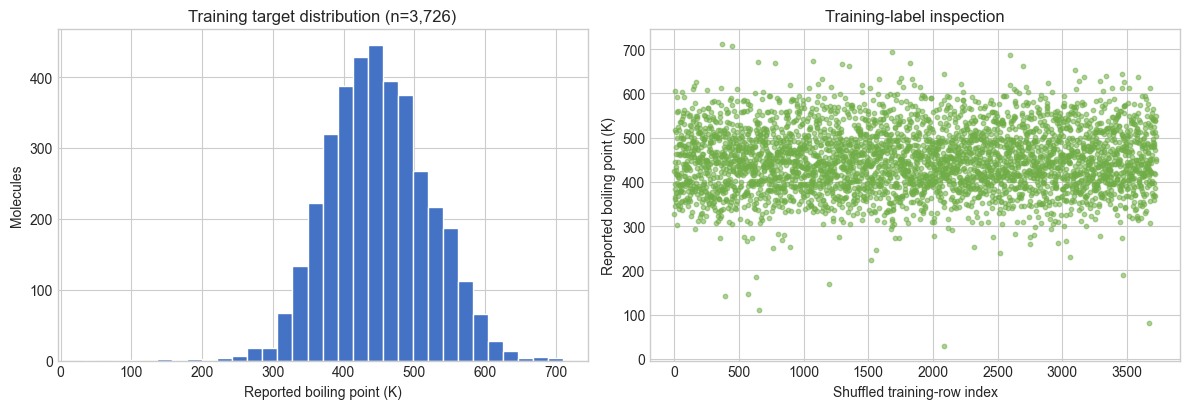

In [5]:
train_table = cleaned.query("split == 'train'").copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(train_table.BP, bins=32, color='#4472C4', edgecolor='white')
axes[0].set(title=f'Training target distribution (n={len(train_table):,})', xlabel='Reported boiling point (K)', ylabel='Molecules')
axes[1].scatter(np.arange(len(train_table)), train_table.BP.sample(frac=1, random_state=SEED).to_numpy(), s=10, alpha=0.55, color='#70AD47')
axes[1].set(title='Training-label inspection', xlabel='Shuffled training-row index', ylabel='Reported boiling point (K)')
fig.tight_layout()
fig.savefig(FIGURES / 'training_target_distribution.png', dpi=220, bbox_inches='tight')
plt.show()


### Build molecular descriptors and fingerprints

Code Summary: Converts SMILES into molecular descriptors and Morgan fingerprints, then saves the feature specification. Boiling points and source identifiers are not used as inputs.


In [6]:
def descriptor_vector(molecule):
    return np.array([
        Descriptors.MolWt(molecule), Descriptors.MolLogP(molecule), rdMolDescriptors.CalcTPSA(molecule),
        Lipinski.NumHDonors(molecule), Lipinski.NumHAcceptors(molecule), Lipinski.NumRotatableBonds(molecule),
        rdMolDescriptors.CalcNumRings(molecule), rdMolDescriptors.CalcNumAromaticRings(molecule),
        rdMolDescriptors.CalcFractionCSP3(molecule), molecule.GetNumHeavyAtoms(), Chem.GetFormalCharge(molecule),
    ], dtype=float)

def make_features(smiles_values, fp_bits):
    """Return deterministic SMILES-derived descriptors and Morgan fingerprints."""
    descriptors, fingerprints = [], []
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=fp_bits)
    for smiles in smiles_values:
        molecule = Chem.MolFromSmiles(smiles)
        if molecule is None or len(Chem.GetMolFrags(molecule)) != 1:
            raise ValueError(f'Unsupported SMILES in feature construction: {smiles!r}')
        descriptors.append(descriptor_vector(molecule))
        bit_vector = generator.GetFingerprint(molecule)
        bit_array = np.zeros((fp_bits,), dtype=np.uint8)
        DataStructs.ConvertToNumpyArray(bit_vector, bit_array)
        fingerprints.append(bit_array)
    return np.asarray(descriptors), np.asarray(fingerprints)

# Chemistry hypotheses: descriptors expose size/polarity/interaction proxies; circular fingerprints
# expose local functional-group and branching environments. Neither is a complete physical model.
all_descriptors, all_fp_512 = make_features(cleaned[SMILES], fp_bits=512)
descriptor_frame = pd.DataFrame(all_descriptors, columns=DESCRIPTOR_NAMES)
descriptor_frame.to_csv(OUTPUT / 'smiles_derived_descriptors.csv', index=False)
representation_spec = {
    'input': 'single-component, RDKit-valid SMILES', 'target': 'BP in K',
    'descriptors': DESCRIPTOR_NAMES, 'fingerprint': {'family': 'Morgan bit vector', 'radius': FP_RADIUS, 'bits': 512},
    'feature_policy': 'all model features are derived from SMILES; BP and source identifiers are excluded',
}
(OUTPUT / 'representation_specification.json').write_text(json.dumps(representation_spec, indent=2), encoding='utf-8')
print('Descriptor matrix:', all_descriptors.shape, '| Morgan-512 matrix:', all_fp_512.shape)
display(descriptor_frame.describe().T[['mean', 'min', 'max']].round(2))


Descriptor matrix: (4658, 11) | Morgan-512 matrix: (4658, 512)


,mean,min,max
MolWt,133.81,16.04,366.07
MolLogP,2.21,-2.33,7.66
TPSA,16.36,0.00,172.56
HBD,0.31,0.00,5.00
HBA,1.07,0.00,8.00
RotatableBonds,2.32,0.00,17.00
RingCount,0.62,0.00,4.00
AromaticRings,0.38,0.00,4.00
FractionCSP3,0.64,0.00,1.00
HeavyAtoms,9.25,1.00,21.00


<h2 style="color:#1D4E89;">Step 6: Algorithm</h2>

        The baseline predicts the training-set median for every molecule. It answers whether structure adds value at all. Two complementary, affordable model families are compared:

        - **Extra Trees:** randomized decision trees that can capture nonlinear effects from compact physical descriptors.
        - **Random Forest:** averaged decision trees that can use descriptors plus local molecular environments from Morgan fingerprints.

        Neither model needs target-derived feature selection or scaling. The representation functions are deterministic and reused unchanged at inference. Tree feature importance is an association within this dataset, not a causal explanation of boiling.


### Define model candidates and a simple baseline

Code Summary: Defines regression metrics and candidate tree models, then fits a training-median baseline as a reference for evaluating useful improvements.


In [7]:
def metrics_frame(y_true, prediction, split_name):
    return {
        'split': split_name,
        'n': int(len(y_true)),
        'MAE_K': float(mean_absolute_error(y_true, prediction)),
        'RMSE_K': float(mean_squared_error(y_true, prediction) ** 0.5),
        'R2': float(r2_score(y_true, prediction)),
    }

def feature_matrix(descriptors, fingerprints, feature_set):
    if feature_set == 'descriptors':
        return descriptors
    if feature_set == 'descriptors_plus_morgan':
        return np.hstack([descriptors, fingerprints])
    raise ValueError(f'Unknown feature set: {feature_set}')

def build_estimator(family, settings):
    common = {'n_estimators': settings['n_estimators'], 'min_samples_leaf': settings['min_samples_leaf'],
              'max_features': settings['max_features'], 'random_state': SEED, 'n_jobs': -1}
    if family == 'extra_trees':
        return ExtraTreesRegressor(**common)
    if family == 'random_forest':
        return RandomForestRegressor(**common)
    raise ValueError(f'Unknown model family: {family}')

split_indices = {name: cleaned.index[cleaned.split == name].to_numpy() for name in ['train', 'validation', 'test']}
y = cleaned[TARGET].to_numpy()
baseline = DummyRegressor(strategy='median').fit(np.zeros((len(split_indices['train']), 1)), y[split_indices['train']])
baseline_validation = baseline.predict(np.zeros((len(split_indices['validation']), 1)))
baseline_test = baseline.predict(np.zeros((len(split_indices['test']), 1)))
print('Training-median baseline validation MAE:', f"{mean_absolute_error(y[split_indices['validation']], baseline_validation):.2f} K")


Training-median baseline validation MAE: 59.35 K


<h2 style="color:#1D4E89;">Step 7: Experiment</h2>

        All experiments use exactly the frozen training and validation rows. The held-out test rows are absent from this section's feature matrices, predictions, and metrics.

        Two practical enhancement ideas are considered: (1) add Morgan environments to compact size/polarity descriptors, or (2) fit a residual correction to a hand-designed physical trend. We evaluate the first option because fingerprints can represent branching and functional-group neighborhoods without assuming a universal physical equation. The descriptor-only model is the controlled ablation.


### Run controlled model and feature experiments

Code Summary: Trains descriptor-only and fingerprint-augmented models on the same splits, recording settings, runtime, and predictions. Model selection uses validation performance rather than test results.


In [8]:
experiment_rows = []

def run_experiment(number, hypothesis, family, feature_set, descriptors, fingerprints, settings, save_model=False):
    """Fit and evaluate only train/validation data; no test arrays are accepted here."""
    experiment_id = f'experiment_{number:03d}'
    folder = EXPERIMENTS / experiment_id
    folder.mkdir(exist_ok=True)
    X = feature_matrix(descriptors, fingerprints, feature_set)
    train_idx, val_idx = split_indices['train'], split_indices['validation']
    model = build_estimator(family, settings)
    started = time.perf_counter()
    model.fit(X[train_idx], y[train_idx])
    elapsed = time.perf_counter() - started
    predictions = {}
    records = []
    for split_name, idx in [('train', train_idx), ('validation', val_idx)]:
        prediction = model.predict(X[idx])
        predictions[split_name] = prediction
        records.append(metrics_frame(y[idx], prediction, split_name))
    prediction_table = pd.concat([
        pd.DataFrame({'canonical_SMILES': cleaned.loc[idx, SMILES].to_numpy(), 'split': split_name,
                      'observed_BP_K': y[idx], 'predicted_BP_K': predictions[split_name]})
        for split_name, idx in [('train', train_idx), ('validation', val_idx)]
    ], ignore_index=True)
    prediction_table.to_csv(folder / 'predictions.csv', index=False)
    validation_record = next(row for row in records if row['split'] == 'validation')
    metadata = {'experiment_id': experiment_id, 'hypothesis': hypothesis, 'model_family': family,
                'feature_set': feature_set, 'settings': settings, 'seed': SEED, 'runtime_seconds': elapsed,
                'metrics': records, 'test_accessed': False}
    (folder / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    if save_model:
        joblib.dump(model, folder / 'model.joblib')
    row = {'experiment_id': experiment_id, 'hypothesis': hypothesis, 'model_family': family,
           'feature_set': feature_set, 'runtime_seconds': elapsed, **{f"validation_{k}": v for k, v in validation_record.items() if k != 'split'},
           'settings_json': json.dumps(settings, sort_keys=True)}
    experiment_rows.append(row)
    return model, row

initial_settings = {'n_estimators': 220, 'min_samples_leaf': 2, 'max_features': 0.65}
experiments = [
    (1, 'A descriptor-only nonlinear model tests whether size and polarity proxies are sufficient.', 'extra_trees', 'descriptors'),
    (2, 'Morgan environments may add functional-group and branching information to descriptors.', 'random_forest', 'descriptors_plus_morgan'),
    (3, 'Extra Trees offers a second model family on the combined representation.', 'extra_trees', 'descriptors_plus_morgan'),
]
initial_models = {}
for number, hypothesis, family, feature_set in experiments:
    model, row = run_experiment(number, hypothesis, family, feature_set, all_descriptors, all_fp_512, initial_settings)
    initial_models[row['experiment_id']] = model

experiment_summary = pd.DataFrame(experiment_rows).sort_values('validation_MAE_K').reset_index(drop=True)
experiment_summary.to_csv(OUTPUT / 'experiment_summary_step7.csv', index=False)
display(experiment_summary[['experiment_id', 'model_family', 'feature_set', 'validation_MAE_K', 'validation_RMSE_K', 'validation_R2', 'runtime_seconds']].round(3))


,experiment_id,model_family,feature_set,validation_MAE_K,validation_RMSE_K,validation_R2,runtime_seconds
0,experiment_003,extra_trees,descriptors_plus_morgan,13.711,27.555,0.866,3.331
1,experiment_002,random_forest,descriptors_plus_morgan,13.861,27.146,0.870,2.375
2,experiment_001,extra_trees,descriptors,14.190,26.368,0.878,0.211


### Compare validation errors against the baseline

Code Summary: Compares validation mean absolute error across experiments and the training-median baseline, showing which approaches improve on a simple constant prediction.


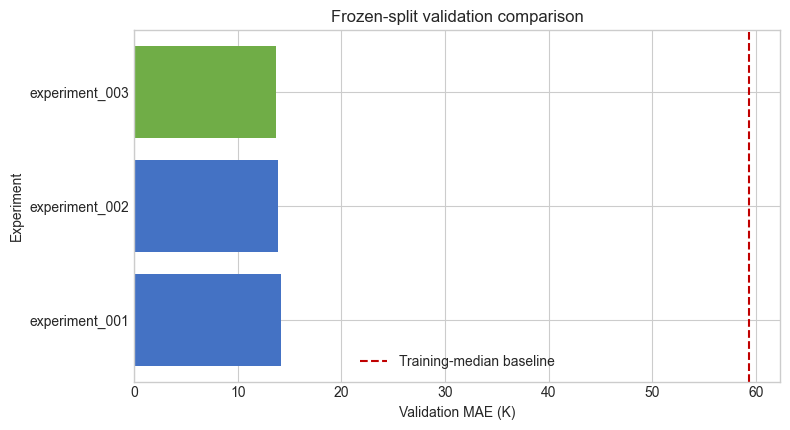

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ordered = experiment_summary.sort_values('validation_MAE_K', ascending=False)
ax.barh(ordered.experiment_id, ordered.validation_MAE_K, color=['#70AD47' if value == ordered.validation_MAE_K.min() else '#4472C4' for value in ordered.validation_MAE_K])
ax.axvline(mean_absolute_error(y[split_indices['validation']], baseline_validation), color='#C00000', linestyle='--', label='Training-median baseline')
ax.set(xlabel='Validation MAE (K)', ylabel='Experiment', title='Frozen-split validation comparison')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'validation_experiment_comparison.png', dpi=220, bbox_inches='tight')
plt.show()


<h2 style="color:#1D4E89;">Step 8: Analysis</h2>

        Validation MAE selects the leading configuration. The table below checks for a large train-to-validation gap and whether the model behaves differently for simple descriptor-defined subgroups. These are limited diagnostic slices, especially when a group is small. We do not use the test set here: Step 9 may still change the representation.


### Analyze validation errors to guide the next experiment

Code Summary: Examines the leading model's training/validation gap and largest validation errors by molecular size to motivate the next experiment.


In [10]:
best_step7 = experiment_summary.iloc[0]
best_step7_id = best_step7.experiment_id
best_predictions = pd.read_csv(EXPERIMENTS / best_step7_id / 'predictions.csv')
train_mae = mean_absolute_error(best_predictions.query("split == 'train'").observed_BP_K, best_predictions.query("split == 'train'").predicted_BP_K)
val_mae = mean_absolute_error(best_predictions.query("split == 'validation'").observed_BP_K, best_predictions.query("split == 'validation'").predicted_BP_K)
print(f"Step 7 leader: {best_step7_id}; validation MAE = {val_mae:.2f} K; train–validation gap = {val_mae - train_mae:.2f} K")

val_index = split_indices['validation']
val_analysis = cleaned.loc[val_index, [SMILES, TARGET]].copy().reset_index(drop=True)
val_analysis['predicted_BP_K'] = best_predictions.query("split == 'validation'").predicted_BP_K.to_numpy()
val_analysis['absolute_error_K'] = (val_analysis.BP - val_analysis.predicted_BP_K).abs()
val_analysis['molecular_weight'] = all_descriptors[val_index, 0]
val_analysis['is_aromatic'] = all_descriptors[val_index, 7] > 0
groups = val_analysis.assign(size_group=pd.qcut(val_analysis.molecular_weight, q=3, duplicates='drop')).groupby('size_group', observed=True).agg(
    n=('BP', 'size'), MAE_K=('absolute_error_K', 'mean'), mean_BP_K=('BP', 'mean')
)
display(groups.round(2))
display(val_analysis.sort_values('absolute_error_K', ascending=False).head(6)[[SMILES, 'BP', 'predicted_BP_K', 'absolute_error_K']].round(2))
print('These errors and group summaries describe model behavior on this split; they do not establish chemical causation.')


Step 7 leader: experiment_003; validation MAE = 13.71 K; train–validation gap = 9.89 K


,n,MAE_K,mean_BP_K
size_group,,,
"(42.080000000000005, 114.188]",157,11.39,390.23
"(114.188, 146.142]",153,10.20,449.89
"(146.142, 288.947]",156,19.49,518.84


,SMILES,BP,predicted_BP_K,absolute_error_K
259,CCCCOC(=O)CC(C)C,175.70,447.54,271.84
300,CC[C@@H](C)CN,96.50,366.64,270.14
286,CCOC(=O)N1CCNCC1,546.20,390.70,155.50
128,CC(C)OC(OC(C)C)C(C)C,431.00,324.63,106.37
231,CCCCCCC(c1ccccc1)c1ccccc1,506.00,605.83,99.83
229,CCCCCCC(=O)Oc1ccccc1,448.65,543.09,94.44


These errors and group summaries describe model behavior on this split; they do not establish chemical causation.


<h2 style="color:#1D4E89;">Step 9: Optimization</h2>

        One focused change tests whether a longer fingerprint retains useful local environments without changing the split, target, model family, or tree settings. This is a bounded representation change, not repeated searching for a preferred score. The validation result decides whether the 512-bit or 1024-bit representation is frozen before the test set is opened.


### Test a revised fingerprint representation

Code Summary: Tests a 1024-bit fingerprint with the leading model family and retains it only if validation error improves. Saves the selected configuration before test evaluation.


In [11]:
all_descriptors_1024, all_fp_1024 = make_features(cleaned[SMILES], fp_bits=1024)
leader_settings = json.loads(best_step7.settings_json)
optimized_model, optimized_row = run_experiment(
    4,
    'A 1024-bit Morgan fingerprint tests whether fewer bit collisions improve the leading validation design.',
    best_step7.model_family,
    'descriptors_plus_morgan',
    all_descriptors_1024,
    all_fp_1024,
    leader_settings,
)
experiment_summary = pd.DataFrame(experiment_rows).sort_values('validation_MAE_K').reset_index(drop=True)
experiment_summary.to_csv(OUTPUT / 'experiment_summary.csv', index=False)
display(experiment_summary[['experiment_id', 'model_family', 'feature_set', 'validation_MAE_K', 'validation_RMSE_K', 'validation_R2']].round(3))

if optimized_row['validation_MAE_K'] < best_step7.validation_MAE_K:
    selected = {'experiment_id': optimized_row['experiment_id'], 'model_family': optimized_row['model_family'],
                'feature_set': optimized_row['feature_set'], 'settings': leader_settings, 'fp_bits': 1024,
                'reason': 'The focused 1024-bit change improved validation MAE.'}
    final_descriptors, final_fingerprints = all_descriptors_1024, all_fp_1024
else:
    selected = {'experiment_id': best_step7_id, 'model_family': best_step7.model_family,
                'feature_set': best_step7.feature_set, 'settings': leader_settings, 'fp_bits': 512,
                'reason': 'The focused 1024-bit change did not improve validation MAE; retain the simpler Step 7 leader.'}
    final_descriptors, final_fingerprints = all_descriptors, all_fp_512
(OUTPUT / 'selected_configuration.json').write_text(json.dumps(selected, indent=2), encoding='utf-8')
print('Frozen selection:', selected['experiment_id'], '|', selected['reason'])


,experiment_id,model_family,feature_set,validation_MAE_K,validation_RMSE_K,validation_R2
0,experiment_004,extra_trees,descriptors_plus_morgan,13.049,25.929,0.882
1,experiment_003,extra_trees,descriptors_plus_morgan,13.711,27.555,0.866
2,experiment_002,random_forest,descriptors_plus_morgan,13.861,27.146,0.870
3,experiment_001,extra_trees,descriptors,14.190,26.368,0.878


Frozen selection: experiment_004 | The focused 1024-bit change improved validation MAE.


<h2 style="color:#1D4E89;">Step 10: Solved?</h2>

        The configuration is now frozen. This is the first point where the held-out test rows are transformed and scored. The same model is trained on the declared training partition, so the validation and test panels remain easy to interpret. No result below is used for further tuning.


### Evaluate the selected model on held-out data

Code Summary: Fits the selected configuration on training data and evaluates it on the independent test set, saving aligned predictions and a comparison with the median baseline.


In [12]:
X_final = feature_matrix(final_descriptors, final_fingerprints, selected['feature_set'])
final_model = build_estimator(selected['model_family'], selected['settings'])
final_model.fit(X_final[split_indices['train']], y[split_indices['train']])

final_predictions = {}
metrics = []
for split_name in ['train', 'validation', 'test']:
    idx = split_indices[split_name]
    prediction = final_model.predict(X_final[idx])
    final_predictions[split_name] = prediction
    metrics.append(metrics_frame(y[idx], prediction, split_name))
final_metrics = pd.DataFrame(metrics).set_index('split')
baseline_metrics = []
for split_name in ['validation', 'test']:
    idx = split_indices[split_name]
    prediction = baseline.predict(np.zeros((len(idx), 1)))
    baseline_metrics.append(metrics_frame(y[idx], prediction, f'{split_name}_median_baseline'))
baseline_metrics = pd.DataFrame(baseline_metrics).set_index('split')

complete_predictions = pd.concat([
    pd.DataFrame({'canonical_SMILES': cleaned.loc[split_indices[split_name], SMILES].to_numpy(), 'split': split_name,
                  'observed_BP_K': y[split_indices[split_name]], 'predicted_BP_K': final_predictions[split_name]})
    for split_name in ['train', 'validation', 'test']
], ignore_index=True)
complete_predictions['residual_K'] = complete_predictions.observed_BP_K - complete_predictions.predicted_BP_K
complete_predictions['absolute_error_K'] = complete_predictions.residual_K.abs()
complete_predictions.to_csv(OUTPUT / 'final_predictions.csv', index=False)
final_metrics.to_csv(OUTPUT / 'final_metrics.csv')
baseline_metrics.to_csv(OUTPUT / 'baseline_metrics.csv')
display(final_metrics.round(2))
display(baseline_metrics.round(2))
test_mae = final_metrics.loc['test', 'MAE_K']
test_baseline_mae = baseline_metrics.loc['test_median_baseline', 'MAE_K']
print('Success criterion:', 'MET' if test_mae < test_baseline_mae else 'NOT MET',
      f'(test MAE {test_mae:.2f} K versus training-median baseline {test_baseline_mae:.2f} K).')


,n,MAE_K,RMSE_K,R2
split,,,,
train,3726,4.05,9.87,0.98
validation,466,13.05,25.93,0.88
test,466,11.57,21.81,0.91


,n,MAE_K,RMSE_K,R2
split,,,,
validation_median_baseline,466,59.35,75.65,-0.01
test_median_baseline,466,57.65,72.73,-0.00


Success criterion: MET (test MAE 11.57 K versus training-median baseline 57.65 K).


### Visualize parity plots and prediction errors

Code Summary: Shows train/validation/test parity plots, test residuals, and the largest held-out errors in kelvin to illustrate the selected model's performance and limitations.


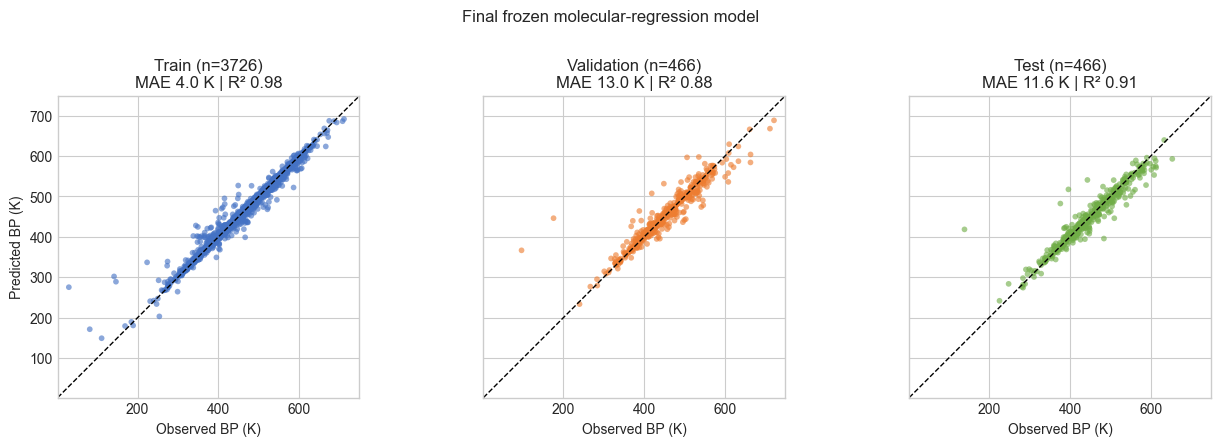

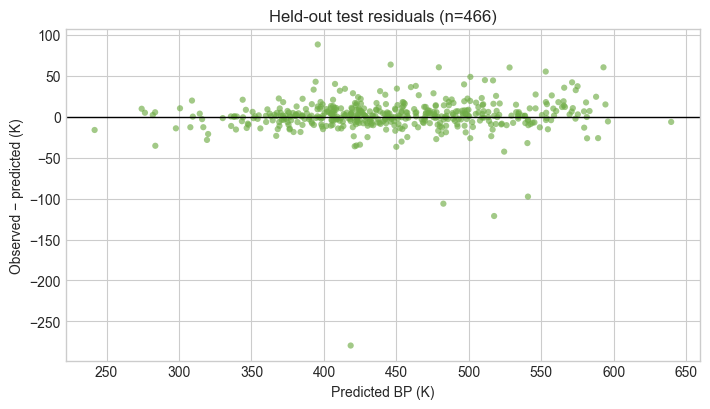

,canonical_SMILES,observed_BP_K,predicted_BP_K,residual_K,absolute_error_K
4511,CC[C@@H](Cl)[C@H](C)Cl,139.00,418.44,-279.44,279.44
4439,CCCCCCC(=O)OCCCCC,396.15,517.41,-121.26,121.26
4229,C=C(C#N)CCC#N,376.20,482.39,-106.19,106.19
4603,N#CC(O)c1ccccc1,443.20,540.75,-97.55,97.55
4506,CCS(=O)CC,484.00,395.73,88.27,88.27
4626,O=CN1CCOCC1,509.70,446.01,63.69,63.69
4571,Cc1ccc(NCCC(C)C)cc1,539.65,479.27,60.38,60.38
4624,O=C1c2ccccc2C(=O)c2ccccc21,653.20,592.84,60.36,60.36


In [13]:
colors = {'train': '#4472C4', 'validation': '#ED7D31', 'test': '#70AD47'}
limits = np.array([complete_predictions.observed_BP_K.min(), complete_predictions.observed_BP_K.max()])
pad = 0.04 * np.diff(limits)[0]
limits = (limits[0] - pad, limits[1] + pad)
fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.2), sharex=True, sharey=True)
for ax, split_name in zip(axes, ['train', 'validation', 'test']):
    subset = complete_predictions.query('split == @split_name')
    ax.scatter(subset.observed_BP_K, subset.predicted_BP_K, s=17, alpha=.62, color=colors[split_name], edgecolor='none')
    ax.plot(limits, limits, 'k--', linewidth=1)
    row = final_metrics.loc[split_name]
    ax.set(title=f"{split_name.title()} (n={len(subset)})\nMAE {row.MAE_K:.1f} K | R² {row.R2:.2f}",
           xlabel='Observed BP (K)', xlim=limits, ylim=limits)
    ax.set_aspect('equal', adjustable='box')
axes[0].set_ylabel('Predicted BP (K)')
fig.suptitle('Final frozen molecular-regression model', y=1.03)
fig.tight_layout()
fig.savefig(FIGURES / 'final_parity_by_split.png', dpi=220, bbox_inches='tight')
plt.show()

test_predictions = complete_predictions.query("split == 'test'").copy()
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.scatter(test_predictions.predicted_BP_K, test_predictions.residual_K, color='#70AD47', alpha=.65, s=20, edgecolor='none')
ax.axhline(0, color='black', linewidth=1)
ax.set(title=f"Held-out test residuals (n={len(test_predictions)})", xlabel='Predicted BP (K)', ylabel='Observed − predicted (K)')
fig.tight_layout()
fig.savefig(FIGURES / 'held_out_test_residuals.png', dpi=220, bbox_inches='tight')
plt.show()
display(test_predictions.sort_values('absolute_error_K', ascending=False).head(8)[['canonical_SMILES', 'observed_BP_K', 'predicted_BP_K', 'residual_K', 'absolute_error_K']].round(2))


### Save the model and predict new molecules

Code Summary: Saves the inference bundle and predicts new SMILES with input checks. Fingerprint similarity provides a rough indication of training-set support, not a calibrated uncertainty estimate.


In [14]:
# Similarity is a local applicability diagnostic: compare each query to the frozen training structures.
fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=selected['fp_bits'])
train_fingerprints = []
for smiles in cleaned.loc[split_indices['train'], SMILES]:
    train_fingerprints.append(fingerprint_generator.GetFingerprint(Chem.MolFromSmiles(smiles)))

artifact = {
    'model': final_model,
    'selected_configuration': selected,
    'descriptor_names': DESCRIPTOR_NAMES,
    'training_smiles': cleaned.loc[split_indices['train'], SMILES].tolist(),
    'support_policy': 'RDKit-valid, single-component SMILES',
}
MODEL_FILE = OUTPUT / 'final_inference_pipeline.joblib'
joblib.dump(artifact, MODEL_FILE, compress=5)

def predict_boiling_point(smiles):
    """Predict one SMILES or a list, returning status and local-support information."""
    values = [smiles] if isinstance(smiles, str) else list(smiles)
    rows = []
    for supplied in values:
        molecule = Chem.MolFromSmiles(supplied) if isinstance(supplied, str) else None
        if molecule is None:
            rows.append({'input_SMILES': supplied, 'canonical_SMILES': None, 'status': 'invalid SMILES',
                         'predicted_BP_K': np.nan, 'predicted_BP_C': np.nan, 'max_training_tanimoto': np.nan,
                         'applicability': 'not evaluated'})
            continue
        if len(Chem.GetMolFrags(molecule)) != 1:
            rows.append({'input_SMILES': supplied, 'canonical_SMILES': Chem.MolToSmiles(molecule), 'status': 'unsupported: multiple components',
                         'predicted_BP_K': np.nan, 'predicted_BP_C': np.nan, 'max_training_tanimoto': np.nan,
                         'applicability': 'not evaluated'})
            continue
        canonical = Chem.MolToSmiles(molecule, canonical=True, isomericSmiles=True)
        descriptors, fingerprint_array = make_features([canonical], selected['fp_bits'])
        x_query = feature_matrix(descriptors, fingerprint_array, selected['feature_set'])
        prediction = float(final_model.predict(x_query)[0])
        query_fp = fingerprint_generator.GetFingerprint(molecule)
        similarity = max(DataStructs.TanimotoSimilarity(query_fp, train_fp) for train_fp in train_fingerprints)
        applicability = 'within common local support' if similarity >= 0.45 else 'low similarity: use cautiously'
        rows.append({'input_SMILES': supplied, 'canonical_SMILES': canonical, 'status': 'ok',
                     'predicted_BP_K': prediction, 'predicted_BP_C': prediction - 273.15,
                     'max_training_tanimoto': similarity, 'applicability': applicability})
    return pd.DataFrame(rows)

demo_smiles = ['CCO', 'c1ccccc1', 'CC(=O)O', 'C(C)(C)(C)O', 'not-a-smiles']
demo = predict_boiling_point(demo_smiles)
demo['already_in_training'] = demo.canonical_SMILES.isin(set(artifact['training_smiles']))
demo.to_csv(OUTPUT / 'inference_demonstration.csv', index=False)
display(demo.round({'predicted_BP_K': 1, 'predicted_BP_C': 1, 'max_training_tanimoto': 2}))


[14:57:58] SMILES Parse Error: syntax error while parsing: not-a-smiles
[14:57:58] SMILES Parse Error: Failed parsing SMILES 'not-a-smiles' for input: 'not-a-smiles'


,input_SMILES,canonical_SMILES,status,predicted_BP_K,predicted_BP_C,max_training_tanimoto,applicability,already_in_training
0,CCO,CCO,ok,353.8,80.6,1.0,within common local support,True
1,c1ccccc1,c1ccccc1,ok,352.0,78.9,1.0,within common local support,True
2,CC(=O)O,CC(=O)O,ok,409.6,136.5,1.0,within common local support,True
3,C(C)(C)(C)O,CC(C)(C)O,ok,364.7,91.5,1.0,within common local support,True
4,not-a-smiles,None,invalid SMILES,NaN,NaN,NaN,not evaluated,False


### Verify inference in a fresh Python process

Code Summary: Reloads the saved model in a fresh Python process and checks that inference works without retraining, preserves row alignment, and rejects unsupported inputs.


In [15]:
# A fresh interpreter reloads the saved pipeline and recomputes features without retraining.
reload_script = OUTPUT / 'reload_check.py'
reload_script.write_text(r"""from pathlib import Path
import joblib
import numpy as np
from rdkit import Chem
from rdkit.Chem import DataStructs, Descriptors, Lipinski, rdFingerprintGenerator, rdMolDescriptors

ROOT = Path(__file__).resolve().parent
artifact = joblib.load(ROOT / 'final_inference_pipeline.joblib')
config = artifact['selected_configuration']
def descriptors(m):
    return np.array([Descriptors.MolWt(m), Descriptors.MolLogP(m), rdMolDescriptors.CalcTPSA(m), Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m), Lipinski.NumRotatableBonds(m), rdMolDescriptors.CalcNumRings(m), rdMolDescriptors.CalcNumAromaticRings(m), rdMolDescriptors.CalcFractionCSP3(m), m.GetNumHeavyAtoms(), Chem.GetFormalCharge(m)], dtype=float)
smiles = 'CCO'
m = Chem.MolFromSmiles(smiles)
fp = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=config['fp_bits']).GetFingerprint(m)
bits = np.zeros((config['fp_bits'],), dtype=np.uint8); DataStructs.ConvertToNumpyArray(fp, bits)
x = descriptors(m).reshape(1, -1) if config['feature_set'] == 'descriptors' else np.hstack([descriptors(m).reshape(1, -1), bits.reshape(1, -1)])
prediction = float(artifact['model'].predict(x)[0])
assert np.isfinite(prediction)
print(f'reload prediction for {smiles}: {prediction:.6f} K')
""", encoding='utf-8')
completed = subprocess.run([sys.executable, str(reload_script)], check=True, capture_output=True, text=True)
print(completed.stdout.strip())

assert not complete_predictions[['observed_BP_K', 'predicted_BP_K']].isna().any().any()
assert np.isfinite(complete_predictions.predicted_BP_K).all()
assert len(complete_predictions) == len(cleaned)
assert (demo.loc[demo.status == 'ok', 'predicted_BP_K'].notna()).all()
assert (demo.loc[demo.status != 'ok', 'predicted_BP_K'].isna()).all()
print('Alignment, finite-prediction, invalid-input, and fresh-reload checks passed.')


reload prediction for CCO: 353.766864 K
Alignment, finite-prediction, invalid-input, and fresh-reload checks passed.


### Step 10 interpretation

        The success criterion is answered by the printed held-out comparison with the training-median baseline. The test metrics estimate performance for a random split of this curated source table, with this feature policy and label definition. They should not be read as an estimate for new chemical scaffolds, mixtures, salts, other pressures, or a new measurement protocol.

        The next scientifically useful experiment is a scaffold-grouped split with repeated cross-validation. That would test whether the apparent value of local structural similarity persists for genuinely new chemical families.


### Save the reproducibility manifest

Code Summary: Records the dataset checksum, software versions, split policy, and selected settings in a manifest so the experiment can be traced and reproduced.


In [16]:
source_checksum = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
manifest = {
    'data_file': str(DATA_FILE.relative_to(REPO)), 'data_sha256': source_checksum, 'data_kind': DATA_KIND,
    'target_units': 'K (from NIST acquisition provenance and cleaning audit)' if DATA_FILE == ACQUIRED_DATA else 'verify fallback provenance',
    'seed': SEED, 'cleaning_policy': 'valid, single-component RDKit molecules with finite BP from 1 to 2000 K; repeated canonical identities use median BP',
    'split_policy': '80/10/10 random split of unique canonical structures; seed 42 then 43',
    'feature_policy': representation_spec, 'selected_configuration': selected,
    'workflow_runtime_seconds': time.perf_counter() - WORKFLOW_STARTED,
    'software': {'python': sys.version, 'platform': platform.platform(), 'pandas': pd.__version__, 'numpy': np.__version__,
                 'scikit_learn': sklearn.__version__, 'rdkit': rdkit.__version__},
    'reproduce': [
        'uv run --locked jupyter nbconvert --to notebook --execute --inplace 01_boiling_point/examples/04_BP_One_Shot_Workflow.ipynb --ExecutePreprocessor.timeout=600',
        'uv run --locked python scripts/ci/validate_notebooks.py',
    ],
    'test_set_access': 'Step 10 only, after selected_configuration.json was written',
}
(OUTPUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Saved manifest:', OUTPUT / 'run_manifest.json')


Saved manifest: C:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code\01_boiling_point\outputs\bp_one_shot_2\run_manifest.json
